# 02 QAOA desde cero: mismo Max-Cut como circuito

Construimos el ansatz QAOA puerta a puerta a partir del QUBO, vemos cómo cualquier función de scheduling cabe en los ángulos y enviamos el circuito a Aer o al hardware de IBM e IonQ.

Referencias: handbook (AQC, annealing digitalizado, QAOA en la práctica) y cuadernos `01-ibm-submission` / `02-iqm-ionq-submission` de la sesión 01.

In [ ]:
%pip install -q qiskit qiskit-algorithms qiskit-aer qiskit-ibm-runtime qiskit-ionq dimod networkx matplotlib pylatexenc

## 1. El QUBO de partida (idéntico al de `05-qubo-max-cut.ipynb`)

Grafo de 5 nodos y 6 aristas. `ExactSolver` nos da la referencia exacta; `to_ising()` nos da los $h_i$ y $J_{ij}$ que dictan las rotaciones del circuito.


In [47]:
import networkx as nx
import numpy as np
import dimod

G = nx.Graph()
G.add_edges_from([(1,2),(1,3),(2,4),(3,4),(3,5),(4,5)])
nodes = list(G.nodes)
n = len(nodes)
Q = np.zeros((n, n))
for u, v in G.edges:
    i, j = nodes.index(u), nodes.index(v)
    Q[i,i] += 1; Q[j,j] += 1; Q[i,j] -= 1; Q[j,i] -= 1
Q = -1.0 * Q  # minimización

bqm = dimod.BQM(Q, "BINARY")
print('Referencia exacta:')
print(dimod.ExactSolver().sample(bqm).truncate(4))

Referencia exacta:
   0  1  2  3  4 energy num_oc.
0  0  1  1  0  0   -5.0       1
1  1  0  0  1  0   -5.0       1
2  0  1  1  0  1   -5.0       1
3  1  0  0  1  1   -5.0       1
['BINARY', 4 rows, 4 samples, 5 variables]


In [48]:
lineal, cuadratico, offset = bqm.to_ising()

print('h =', dict(lineal))
print('J =', {(i, j): round(v, 3) for (i, j), v in cuadratico.items()})
print('offset =', round(offset, 3))

h = {0: np.float64(0.0), 1: np.float64(0.0), 2: np.float64(0.0), 3: np.float64(0.0), 4: np.float64(0.0)}
J = {(1, 0): np.float64(0.5), (2, 0): np.float64(0.5), (3, 1): np.float64(0.5), (3, 2): np.float64(0.5), (4, 2): np.float64(0.5), (4, 3): np.float64(0.5)}
offset = -3.0


## 2. De Ising a puertas: bloques de coste y mixer

El Hamiltoniano de coste es diagonal, así que su evolución se factoriza:
$U_C(\gamma) = \prod_i R_Z(2\gamma h_i)\prod_{i<j} R_{ZZ}(2\gamma J_{ij})$, y el mixer $U_B(\beta) = \prod_i R_X(2\beta)$ mueve amplitud entre autoestados del coste. Sin mixer, QAOA no optimiza nada (solo añadiría fases).


Puertas por capa: 5 Rz + 6 Rzz + 5 Rx = {'rzz': 6, 'h': 5, 'rz': 5, 'rx': 5, 'measure': 5, 'barrier': 1}


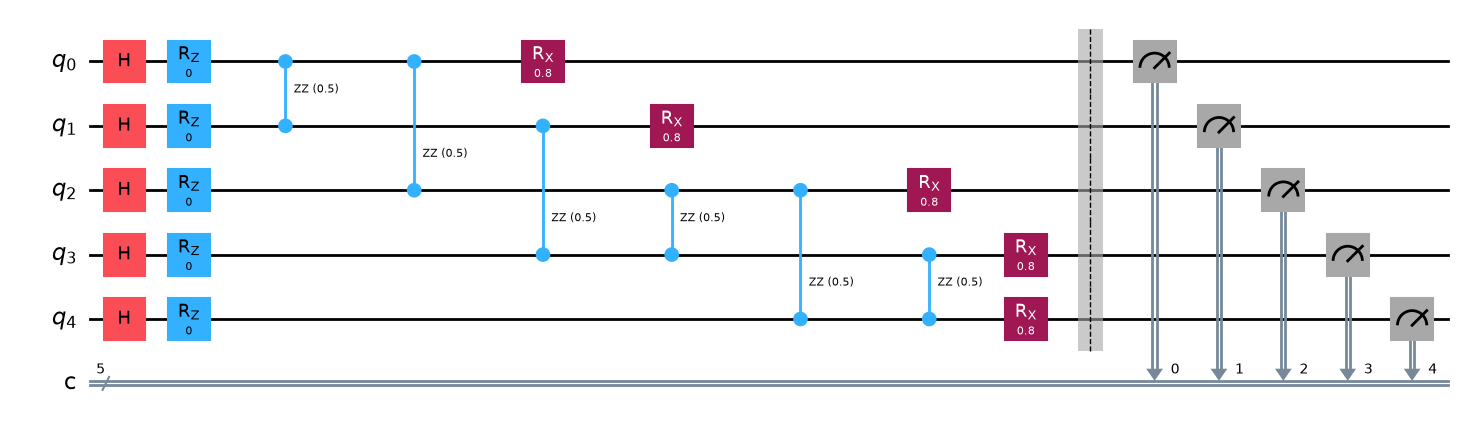

In [49]:
from qiskit import QuantumCircuit

# Z + ZZ
def bloque_coste(gamma, lineal, cuadratico, n):
    qc = QuantumCircuit(n, name=f'C({gamma:.2f})')
    for i, h in lineal.items():
        qc.rz(2 * gamma * h, i)
    for (i, j), J in cuadratico.items():
        qc.rzz(2 * gamma * J, i, j)
    return qc

# X
def bloque_mixer(beta, n):
    qc = QuantumCircuit(n, name=f'M({beta:.2f})')
    qc.rx(2 * beta, list(range(n)))
    return qc

def circuito_qaoa(gammas, betas, lineal, cuadratico, n):
    qc = QuantumCircuit(n, n)
    qc.h(list(range(n)))  # |s> = |+>^n, fundamental de H_init
    for gamma, beta in zip(gammas, betas):
        qc = qc.compose(bloque_coste(gamma, lineal, cuadratico, n))
        qc = qc.compose(bloque_mixer(beta, n))
    qc.measure_all(add_bits=False)
    return qc

qc1 = circuito_qaoa([0.5], [0.4], lineal, cuadratico, n)
print('Puertas por capa: 5 Rz + 6 Rzz + 5 Rx =', dict(qc1.count_ops()))
qc1.draw('mpl', fold=-1)


## 3. La función de scheduling la eliges tú

Annealing digitalizado = fijar la curva $\lambda(t)$ a mano y traducirla a ángulos ($\gamma_k \propto \lambda_k$, $\beta_k \propto 1-\lambda_k$). QAOA = dejar esos ángulos libres para que el optimizador encuentre la mejor curva de esta instancia.

Cuatro curvas clásicas, todas con $\lambda \in [0, 1]$:

* **Lineal** $\lambda(s) = s$: referencia neutra, velocidad constante.
* **Lenta al inicio** $\lambda(s) = s^2$: pasa más pasos cerca del mixer (explora), llega rápido al problema.
* **Lenta al final** $\lambda(s) = 1-(1-s)^2$: corre al principio y frena cerca del problema, donde el *gap* suele estrecharse.
* **Cosenoidal** $\lambda(s) = (1-\cos(\pi s))/2$: curva en S, suave en ambos extremos; frena al salir del mixer y al llegar al problema.

Regla física: ve despacio donde el *gap* $g(s) = E_1(s)-E_0(s)$ se estrecha (el $s^\star$ de las diapositivas). Por eso la lenta al final y la cosenoidal suelen rendir mejor que la lineal con el mismo $p$.


lineal | gammas: [0.15, 0.3, 0.45, 0.6] | betas: [0.45, 0.3, 0.15, 0.0]
lenta-inicio | gammas: [0.04, 0.15, 0.34, 0.6] | betas: [0.56, 0.45, 0.26, 0.0]
lenta-final | gammas: [0.26, 0.45, 0.56, 0.6] | betas: [0.34, 0.15, 0.04, 0.0]
coseno | gammas: [np.float64(0.09), np.float64(0.3), np.float64(0.51), np.float64(0.6)] | betas: [np.float64(0.51), np.float64(0.3), np.float64(0.09), np.float64(0.0)]


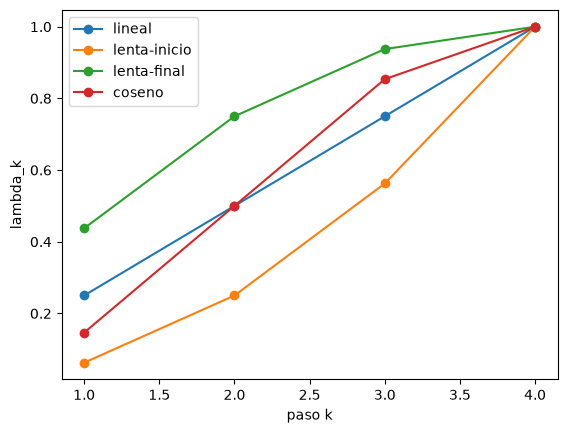

In [50]:
import matplotlib.pyplot as plt
import numpy as np

def rampa_lineal(p):
    return [(k + 1) / p for k in range(p)]

def rampa_lenta_inicio(p):
    return [((k + 1) / p) ** 2 for k in range(p)]

def rampa_lenta_final(p):
    return [1 - (1 - (k + 1) / p) ** 2 for k in range(p)]

def rampa_coseno(p):
    return [(1 - np.cos(np.pi * (k + 1) / p)) / 2 for k in range(p)]

SCHEDULES = {
    'lineal': rampa_lineal,
    'lenta-inicio': rampa_lenta_inicio,
    'lenta-final': rampa_lenta_final,
    'coseno': rampa_coseno,
}

p = 4
for nombre, f in SCHEDULES.items():
    rampa = f(p)
    gammas = [0.6 * l for l in rampa]
    betas = [0.6 * (1 - l) for l in rampa]
    print(nombre, '| gammas:', [round(g, 2) for g in gammas], '| betas:', [round(b, 2) for b in betas])

xs = list(range(1, p + 1))
for nombre, f in SCHEDULES.items():
    plt.plot(xs, f(p), marker='o', label=nombre)
plt.xlabel('paso k'); plt.ylabel('lambda_k'); plt.legend(); plt.show()


### De la curva al circuito: annealing digitalizado con el schedule cosenoidal

Elegimos la curva en S y la traducimos capa a capa: en el paso $k$, $\gamma_k = 0.6\,\lambda_k$ abre el bloque de coste y $\beta_k = 0.6\,(1-\lambda_k)$ abre el mixer. Las primeras capas son casi todo mixer (exploran desde $|+\rangle^{\otimes n}$), las últimas casi todo coste (fijan el problema). El circuito de abajo es exactamente ese: H, luego un bloque C–M por capa.


In [52]:
rampa = rampa_coseno(p)
gammas_cos = [0.6 * l for l in rampa]
betas_cos = [0.6 * (1 - l) for l in rampa]

print(f'{"k":>2} {"lambda":>7} {"gamma":>7} {"beta":>7}')
for k, (l, g, b) in enumerate(zip(rampa, gammas_cos, betas_cos), start=1):
    print(f'{k:>2} {l:>7.3f} {g:>7.3f} {b:>7.3f}')

 k  lambda   gamma    beta
 1   0.146   0.088   0.512
 2   0.500   0.300   0.300
 3   0.854   0.512   0.088
 4   1.000   0.600   0.000


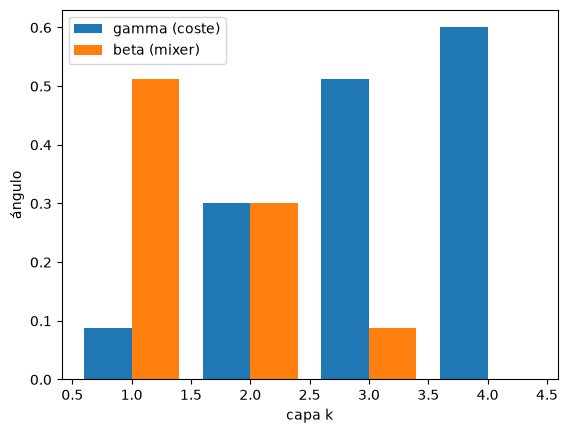

In [53]:
xs = list(range(1, p + 1))
plt.bar([x - 0.2 for x in xs], gammas_cos, width=0.4, label='gamma (coste)')
plt.bar([x + 0.2 for x in xs], betas_cos, width=0.4, label='beta (mixer)')
plt.xlabel('capa k'); plt.ylabel('ángulo'); plt.legend(); plt.show()

Operaciones: {'rzz': 24, 'rz': 20, 'rx': 20, 'h': 5, 'measure': 5, 'barrier': 1}


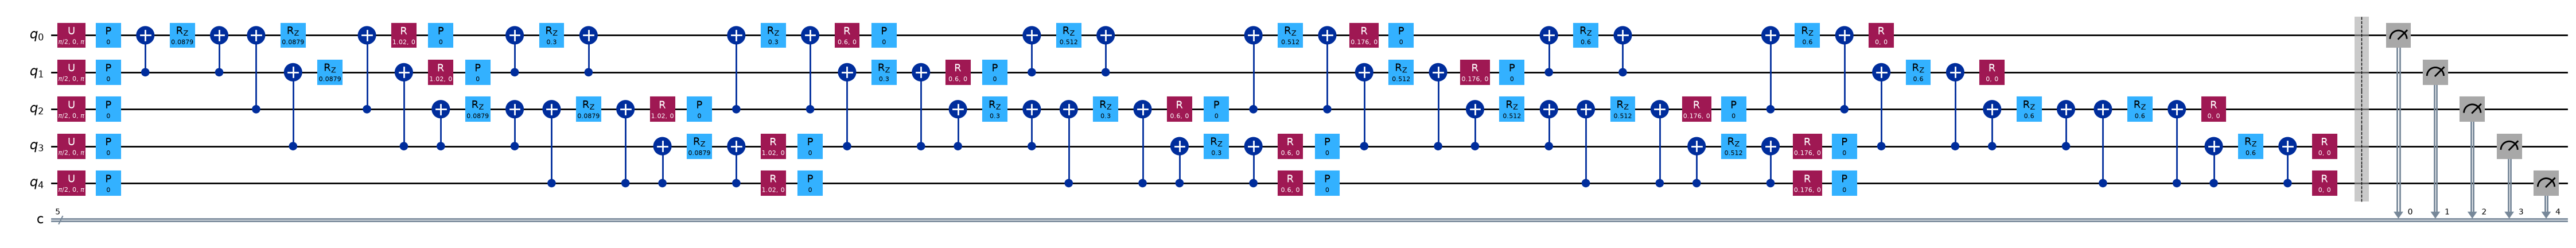

In [54]:
qc_cos = circuito_qaoa(gammas_cos, betas_cos, lineal, cuadratico, n)
print('Operaciones:', dict(qc_cos.count_ops()))
qc_cos.decompose().draw('mpl', fold=-1)

## 4. Annealing digitalizado con Aer: cuatro schedulings fijos, cero optimizador

Muestreamos cada circuito y evaluamos el corte con la matriz Q (invirtiendo el orden de bits de Qiskit, qubit 0 a la derecha).


In [55]:
from qiskit_aer import AerSimulator

def energia(bitstr, Q):
    x = np.array([int(b) for b in bitstr[::-1]])  # qubit 0 primero
    return float(x @ Q @ x)

sim = AerSimulator()
for nombre, f in SCHEDULES.items():
    rampa = f(p)
    qc = circuito_qaoa([0.6 * l for l in rampa], [0.6 * (1 - l) for l in rampa], lineal, cuadratico, n)
    counts = sim.run(qc, shots=2000).result().get_counts(qc)
    mejor = min(counts, key=lambda s: energia(s, Q))
    print(f'{nombre}: mejor={mejor} E={energia(mejor, Q):.1f} shots={counts[mejor]}')


lineal: mejor=01001 E=-5.0 shots=6
lenta-inicio: mejor=10110 E=-5.0 shots=11
lenta-final: mejor=01101 E=-4.0 shots=9
coseno: mejor=10110 E=-5.0 shots=5


In [ ]:
# TODO en clase: plot_histogram de dos opciones y fracción de muestras óptimas (%)

## 5. QAOA optimizado: la curva la aprende COBYLA

Mismo Hamiltoniano, ahora con $\gamma, \beta$ libres (clase `QAOA` de `qiskit-algorithms`, como en el handbook). Comparamos $p=1,2,4$ contra las rampas fijas. `StatevectorSampler` simula localmente y estima los resultados con un número finito de muestras; no envía trabajos a IBM. En la gráfica sumamos el `offset` de Ising para comparar con la energía exacta del QUBO. Las fluctuaciones reflejan el muestreo y las evaluaciones del optimizador, no una convergencia necesariamente monótona.


p = 1 | <H_QUBO> = -4.123
p = 2 | <H_QUBO> = -4.241
p = 4 | <H_QUBO> = -4.387


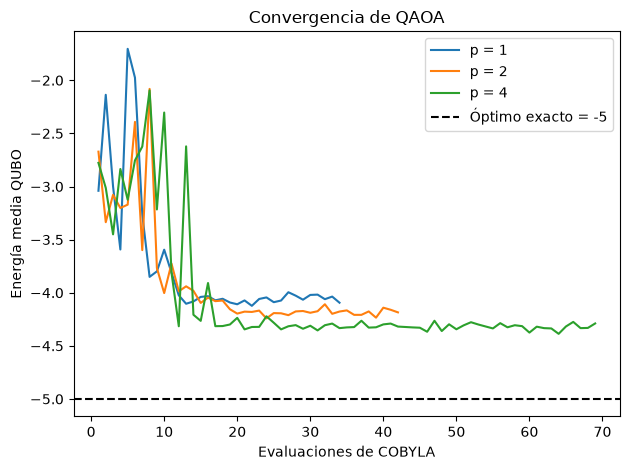

In [40]:
import warnings
import matplotlib.pyplot as plt
from scipy.sparse import SparseEfficiencyWarning
from qiskit_algorithms.minimum_eigensolvers import QAOA
from qiskit_algorithms.optimizers import COBYLA
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import SparsePauliOp

# OJO convención Qiskit (little-endian): el qubit 0 es el carácter de la
# derecha, igual que en el ayudante q0_first de la sesión 01.
terminos = []
for i, h in lineal.items():
    s = ['I'] * n
    s[n - 1 - i] = 'Z'
    terminos.append((''.join(s), float(h)))
for (i, j), J in cuadratico.items():
    s = ['I'] * n
    s[n - 1 - i] = 'Z'
    s[n - 1 - j] = 'Z'
    terminos.append((''.join(s), float(J)))
H_op = SparsePauliOp.from_list(terminos)

historial = {}
for reps in [1, 2, 4]:
    evaluaciones, energias = [], []
    def registrar(evaluacion, parametros, energia, metadatos):
        evaluaciones.append(evaluacion)
        energias.append(float(energia) + offset)

    qaoa = QAOA(StatevectorSampler(), COBYLA(maxiter=100), reps=reps, callback=registrar)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', SparseEfficiencyWarning)
        r = qaoa.compute_minimum_eigenvalue(H_op)
    historial[reps] = (evaluaciones, energias)
    print('p =', reps, '| <H_QUBO> =', round(float(r.optimal_value) + offset, 3))

for reps, (evaluaciones, energias) in historial.items():
    plt.plot(evaluaciones, energias, label=f'p = {reps}')
optimo = float(dimod.ExactSolver().sample(bqm).first.energy)
plt.axhline(optimo, color='black', linestyle='--', label=f'Óptimo exacto = {optimo:g}')
plt.xlabel('Evaluaciones de COBYLA'); plt.ylabel('Energía media QUBO')
plt.title('Convergencia de QAOA'); plt.legend(); plt.tight_layout(); plt.show()

In [ ]:
# TODO en clase: qaoa.ansatz.decompose().draw() y comparar con el circuito manual de la sección 2

## 6. Envío a hardware cloud (mismo circuito, tres destinos)

Igual que en la sesión 01: primero Aer en local. IBM e IonQ requieren credenciales, acceso al QPU elegido y créditos. Cada envío pide confirmación explícita: comprueba antes el coste y la disponibilidad en la consola del proveedor. IBM requiere una instancia de IBM Quantum Platform (CRN); en IonQ selecciona un backend de hardware disponible para tu cuenta.


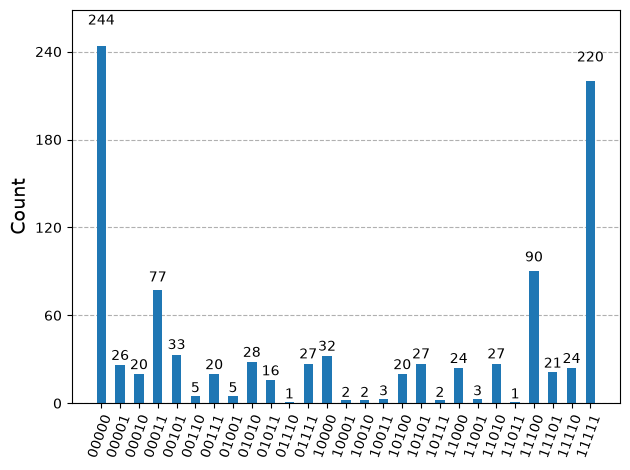

In [42]:
from qiskit.visualization import plot_histogram

qc_envio = circuito_qaoa([0.5, 0.4], [0.3, 0.2], lineal, cuadratico, n)
counts = AerSimulator().run(qc_envio, shots=1000).result().get_counts(qc_envio)
plot_histogram(counts)

In [43]:
import os
from getpass import getpass
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2

token_ibm = os.environ.get('QISKIT_IBM_TOKEN') or getpass('IBM Cloud API key: ')

service_ibm = QiskitRuntimeService(channel='ibm_quantum_platform', token=token_ibm)
backends_ibm = service_ibm.backends(simulator=False, operational=True)

print('Backends IBM disponibles:', [backend.name for backend in backends_ibm])


qiskit_runtime_service._discover_account:WARNING:2026-11-20 20:12:21,900: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-11-20 20:12:25,237: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: Prueba. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-20 20:12:25,237: Loading instance: Prueba, plan: open


Backends IBM disponibles: ['ibm_fez', 'ibm_kingston', 'ibm_marrakesh']


In [ ]:
nombre_ibm = "ibm_fez"

backend_ibm = next((backend for backend in backends_ibm if backend.name == nombre_ibm), None)
if backend_ibm is None:
    raise ValueError('Selecciona uno de los backends disponibles.')
isa_ibm = generate_preset_pass_manager(backend=backend_ibm, optimization_level=1).run(qc_envio)
if input(f'Enviar 1000 shots a {nombre_ibm} (puede consumir créditos). Escribe ENVIAR: ').strip() == 'ENVIAR':
    job_ibm = SamplerV2(mode=backend_ibm).run([isa_ibm], shots=1000)
    print('Job IBM:', job_ibm.job_id())
else:
    print('Envío IBM cancelado.')

qiskit_runtime_service.backends:WARNING:2026-11-20 20:15:32,085: Using instance: Prueba, plan: open


Job IBM: dc09olds2omc7388vr6g


### QAOA variacional en hardware IBM (opcional, con coste en planes de pago)

Hasta aquí el hardware solo ha *muestreado* un circuito con ángulos fijos. El paso siguiente es mover el **bucle variacional completo** a la QPU: el mismo `QAOA` de `qiskit_algorithms` acepta un sampler de Runtime (`SamplerV2` dentro de una `Session`) en lugar del `StatevectorSampler` local. Mismo código, distinto backend. Cada evaluación de COBYLA es un job real en la QPU (lento y con coste), así que la primera toma de contacto usa `reps=1` y pocas iteraciones: no busca convergencia, solo verifica el camino completo.

In [ ]:
from qiskit_ibm_runtime import Session, SamplerV2 as SamplerRuntime
from qiskit_algorithms.minimum_eigensolvers import QAOA
from qiskit_algorithms.optimizers import COBYLA

with Session(backend=backend_ibm) as sesion:
    qaoa_hw = QAOA(SamplerRuntime(mode=sesion), COBYLA(maxiter=25), reps=1)
    resultado_hw = qaoa_hw.compute_minimum_eigenvalue(H_op)

energia_hw = float(resultado_hw.optimal_value) + offset
optimo = float(dimod.ExactSolver().sample(bqm).first.energy)
print(f'Energía QAOA en hardware: {energia_hw:.3f} | óptimo exacto: {optimo:g}')

## Para clase

- Pedid que identifiquen cada bloque del `ansatz.decompose()` con la sección 2.
- Pregunta: ¿a qué scheduling equivale el par $(\gamma, \beta)$ que encontró COBYLA?
- Degeneración $Z_2$: cada corte y su complemento empatan, esperad picos gemelos (`01101`/`10010`).
